In [1]:
import numpy as np
import matplotlib.pyplot as plt 
import scipy.integrate as itg

\begin{pmatrix} x’\ y’\ z’ \end{pmatrix}

\begin{pmatrix}
\cos\omega t & \sin\omega t & 0\\
-\sin\omega t & \cos\omega t & 0\\
0 & 0 & 1
\end{pmatrix}

\begin{pmatrix} x\ y\ z \end{pmatrix}


In [17]:
def RV(state, omega, t):
    """
    Matriz de rotación para una velocidad angular que tiene 
    componente únicamente en el eje z.
    """
    omega = np.linalg.norm(omega)
    theta = omega * ts

    rotated = np.empty_like(state, dtype = float)

    rotated[:, 0] = (
        np.cos(theta) * state[:, 0]
        - np.sin(theta) * state[:, 1]
    )

    rotated[:, 1] = (
        np.sin(theta) * state[:, 0]
        + np.cos(theta) * state[:, 1]
    )

    rotated[:, 2] = state[:, 2]

    return rotated

# def RinV(state, omega, t): 
#     """
#     Inversa de la matriz de rotación anterior
#     """
#     R = np.array([[np.cos(omega*t), np.sin(omega*t), 0],
#                  [-np.sin(omega*t), np.cos(omega*t), 0],
#                  [0,0,1]])
#     RT = R.T
#     inv_transformation = RT@state
#     return inv_transformation

In [14]:
# Código para definir las ecuaciones de movimiento del sistema

"""
Condiciones iniciales del sistema
"""

kpc = 1.0                 # already in code length units
kms_to_code = 1.0/10.0    # 1 code velocity unit = 10 km/s

x0, y0_, z0 = 8.0, 0.0, 0.0 #0.021         # kpc: R ~ 8 kpc, slightly above the plane
vx0, vy0, vz0 = 0.0*kms_to_code, 220.0*kms_to_code, 0.0*kms_to_code  # km/s -> code units

state0 = np.array([x0, y0_, z0, vx0, vy0, vz0])

# Integration will be till 5 Gyrs
time_unit_Gyr = 0.0978
t_end_Gyr = 5
t_end = t_end_Gyr / time_unit_Gyr  # Code units

h = 0.00005
number_steps = int(t_end/h)

"""
Cálculo de las contribuciones de cada uno de los 
componentes del potencial galáctico en la aceleración.
"""

M3 = 4615.
a3 = 12.

def halo(x, R):
    a = -(1.02*M3*(x/R))*((R/a3)**2.02)
    b = R*(1+(R/a3)**1.02)
        
    c = M3 * x * ((R/a3)**(1.02)) / (a3 * R**2)
    d = 1 + (R/a3)**(1.02)
        
    halo = c / d
    return halo

def acc(v): 
    x, y, z = v[0], v[1], v[2]
    R = np.sqrt(x**2 + y**2 + z**2) # kpc units
    truncation = 100
    R = np.minimum(R, truncation)
    R  = max(R, 1e-6)
    
    # Central mass
    M1 = 606.
    b1 = 0.3873
    
    dphi_x1 =  M1*x/(x**2 + y**2 + z**2 + b1**2)**(3/2)
    dphi_y1 =  M1*y/(x**2 + y**2 + z**2 + b1**2)**(3/2)
    dphi_z1 =  M1*z/(x**2 + y**2 + z**2 + b1**2)**(3/2) 
    
    # Disk component
    M2 = 3690.
    a2 = 5.3178
    b2 = 0.25
    
    dphi_x2 = M2*x / (x**2 + y**2 + (a2 + np.sqrt(z**2 + b2**2))**2)**(3/2)
    dphi_y2 = M2*y / (x**2 + y**2 + (a2 + np.sqrt(z**2 + b2**2))**2)**(3/2)
    dphi_z2 = M2*z*(a2 + np.sqrt(z**2 + b2**2))/(np.sqrt(z**2 + b2**2)*(np.sqrt(x**2 + y**2 + (a2 + np.sqrt(z**2 + b2**2))**2))**3)
    
    # Halo
    
    dphi_x3 = halo(x, R)
    dphi_y3 = halo(y, R)
    dphi_z3 = halo(z, R)
    
    dphi_x = dphi_x1 + dphi_x2 + dphi_x3
    dphi_y = dphi_y1 + dphi_y2 + dphi_y3
    dphi_z = dphi_z1 + dphi_z2 + dphi_z3

    acx, acy, acz = -dphi_x, -dphi_y, -dphi_z
    return np.array([acx, acy, acz])

"""
Cálculo de las fuerzas ficticias añadidas al hacer el 
cambio de marco de referencia del inercial al no inercial
"""

def centrifugal(v, omega):
    term1 = np.cross(omega, v)
    ac_centrifuga = np.cross(omega, term1)
    return ac_centrifuga

def coriolis(vel, omega):
    cor = 2*np.cross(omega, vel)
    return cor

def v_r(v, omega):
    r = np.array([v[0], v[1], v[2]])
    vs = np.array([v[3], v[4], v[5]])
    vr = vs - np.cross(omega, r)
    return vr

"""
Definción de las ecuaciones de movimiento en el marco inercial
"""

def f(t, state):
    x, y, z, vx, vy, vz = state
    v = np.array([x,y,z])
    ax, ay, az = acc(v)
    return np.array([vx, vy, vz, ax, ay, az])

"""
Definición de la ecuación de movimiento a integrar en el marco no inercial
"""

def f_nonin(t, state):

    """
    Cantidades en el marco de referencia inercial
    """
    x, y, z, vx, vy, vz = state # Estado en el marco de referencia inercial
    
    v = np.array([x,y,z]) # Vector de posición         
    vel = np.array([vx, vy, vz]) # Velocidad en el marco de referencia inercial
    ax, ay, az = acc(v) # Aceleraciones en el marco de referencia inercial

    """
    Cantidades en el marco de referencia no inercial
    """
    vel_ = v_r(state, omega)
    vx_, vy_, vz_ = vel_

    """
    Aceleraciones por las fuerzas ficticias
    """
    ac_c = centrifugal(v, omega)
    f_cor = coriolis(vel_, omega)
    fic = ac_c + f_cor

    """
    Cálculo de las aceleraciones en el marco no inercial
    """
    n_inx, n_iny, n_inz = ax - fic[0], ay - fic[1], az - fic[2]
    
    return np.array([vx_, vy_, vz_, n_inx, n_iny, n_inz])



In [4]:
"""
Ejemplo para transformar del marco inercial al no inercial
Resolvemos en el marco inercial
"""
solver = itg.RK45(f, 0, state0, t_end, max_step = 0.0005)

ts, soly = [solver.t], [solver.y.copy()]

while solver.status == 'running':
    solver.step()                # Advances one adaptive RK45 step
    ts.append(solver.t)          # These are the time steps
    soly.append(solver.y.copy()) # These is the solution for each step

soly = np.array(soly)
ts = np.array(ts)

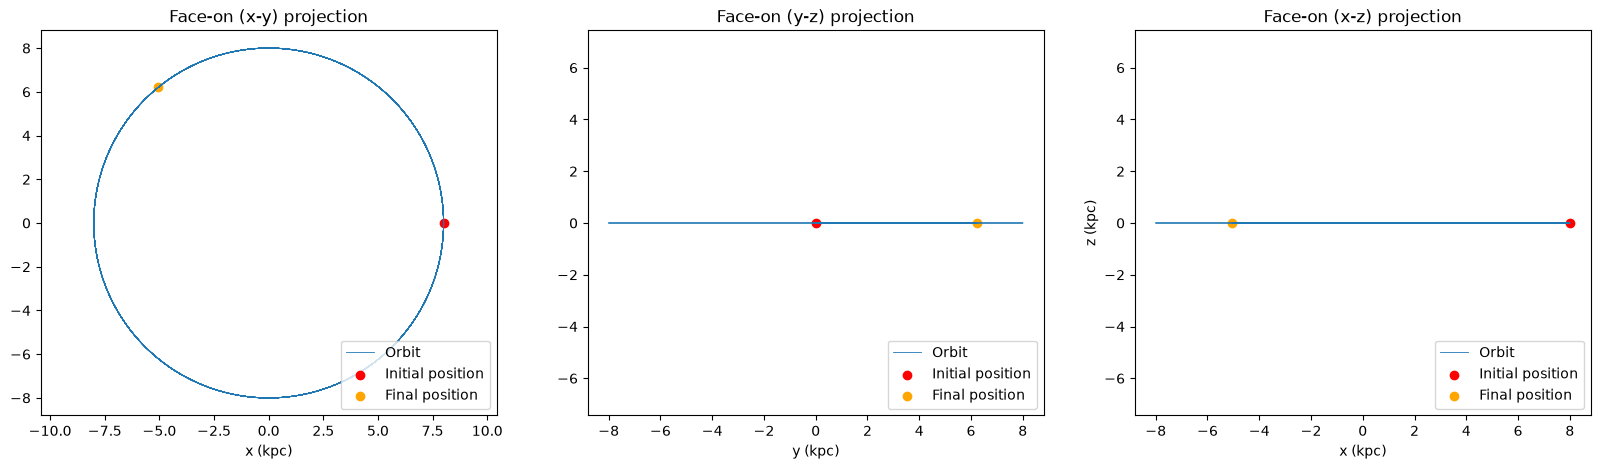

In [5]:
"""
Gráficas de las órbitas en el marco inercial
"""

fig, axes = plt.subplots(1, 3, figsize = (20,5))

axes[0].plot(soly[:,0], soly[:,1], lw=0.6, label = "Orbit")
axes[0].scatter(state0[0], state0[1], color = "r", label = "Initial position")
axes[0].scatter(soly[-1,0], soly[-1,1], color = "orange", label = "Final position")
axes[0].set_xlabel('x (kpc)'); plt.ylabel('y (kpc)')
axes[0].set_title('Face-on (x-y) projection')
axes[0].legend(loc = 4)
axes[0].axis("equal")

axes[1].plot(soly[:,1], soly[:,2], lw=0.6, label = "Orbit")
axes[1].scatter(state0[1], state0[2], color = "r", label = "Initial position")
axes[1].scatter(soly[-1,1], soly[-1,2], color = "orange", label = "Final position")
axes[1].set_xlabel('y (kpc)'); plt.ylabel('z (kpc)')
axes[1].set_title('Face-on (y-z) projection')
axes[1].legend(loc = 4)
axes[1].axis("equal")

axes[2].plot(soly[:,0], soly[:,2], lw=0.6, label = "Orbit")
axes[2].scatter(state0[0], state0[2], color = "r", label = "Initial position")
axes[2].scatter(soly[-1,0], soly[-1,2], color = "orange", label = "Final position")
axes[2].set_xlabel('x (kpc)'); plt.ylabel('z (kpc)')
axes[2].set_title('Face-on (x-z) projection')
axes[2].legend(loc = 4)
axes[2].axis("equal")

#plt.savefig("./images/orbits_each_planeRK45.png")
plt.show()

In [18]:
omega = np.array([0., 0., -2.3])
soly_rot = RV(soly[:, :3], omega, ts)

In [19]:
soly_rot

array([[8.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [7.99999995e+00, 8.88057318e-04, 0.00000000e+00],
       [7.99999404e+00, 9.76862809e-03, 0.00000000e+00],
       ...,
       [7.18292582e+00, 3.52543890e+00, 0.00000000e+00],
       [7.17399833e+00, 3.54355868e+00, 0.00000000e+00],
       [7.17395217e+00, 3.54365206e+00, 0.00000000e+00]],
      shape=(102253, 3))

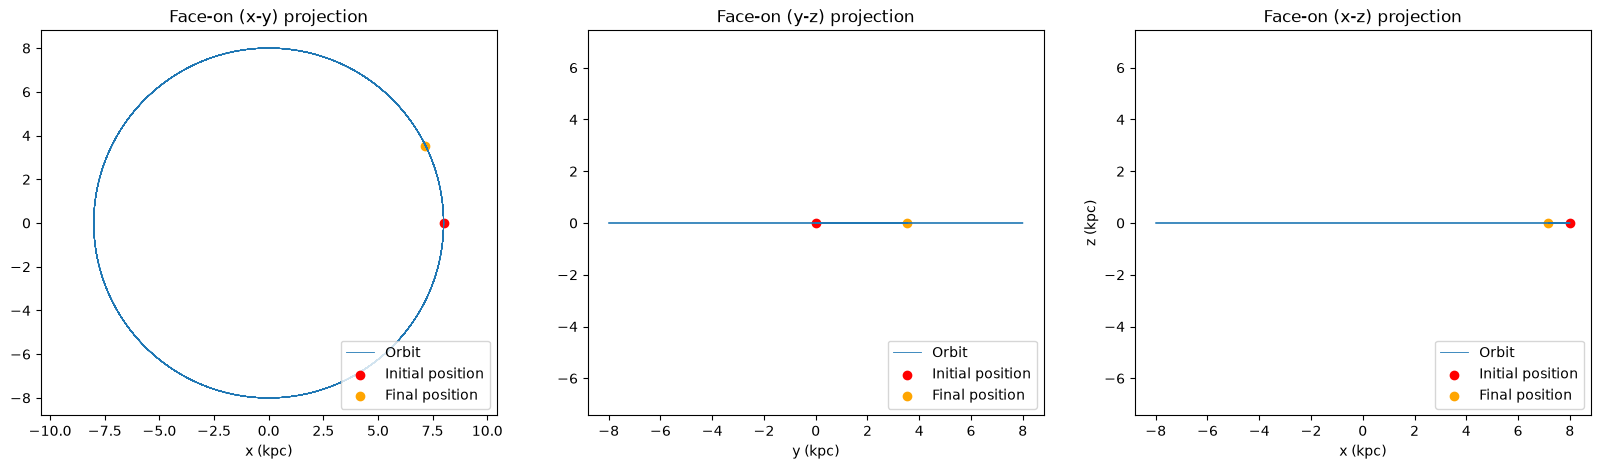

In [20]:
fig, axes = plt.subplots(1, 3, figsize = (20,5))

axes[0].plot(soly_rot[:,0], soly_rot[:,1], lw=0.6, label = "Orbit")
axes[0].scatter(state0[0], state0[1], color = "r", label = "Initial position")
axes[0].scatter(soly_rot[-1,0], soly_rot[-1,1], color = "orange", label = "Final position")
axes[0].set_xlabel('x (kpc)'); plt.ylabel('y (kpc)')
axes[0].set_title('Face-on (x-y) projection')
axes[0].legend(loc = 4)
axes[0].axis("equal")

axes[1].plot(soly_rot[:,1], soly_rot[:,2], lw=0.6, label = "Orbit")
axes[1].scatter(state0[1], state0[2], color = "r", label = "Initial position")
axes[1].scatter(soly_rot[-1,1], soly_rot[-1,2], color = "orange", label = "Final position")
axes[1].set_xlabel('y (kpc)'); plt.ylabel('z (kpc)')
axes[1].set_title('Face-on (y-z) projection')
axes[1].legend(loc = 4)
axes[1].axis("equal")

axes[2].plot(soly_rot[:,0], soly_rot[:,2], lw=0.6, label = "Orbit")
axes[2].scatter(state0[0], state0[2], color = "r", label = "Initial position")
axes[2].scatter(soly_rot[-1,0], soly_rot[-1,2], color = "orange", label = "Final position")
axes[2].set_xlabel('x (kpc)'); plt.ylabel('z (kpc)')
axes[2].set_title('Face-on (x-z) projection')
axes[2].legend(loc = 4)
axes[2].axis("equal")

#plt.savefig("./images/orbits_each_planeRK45.png")
plt.show()